In [ ]:
# EDA on Retail Sales Data

## Objective
'''
To perform Exploratory Data Analysis on a retail sales dataset
to identify sales trends, customer behaviour, product performance,
and actionable business insights.
'''

'\nTo perform Exploratory Data Analysis on a retail sales dataset\nto identify sales trends, customer behaviour, product performance,\nand actionable business insights.\n'

In [ ]:
## 1. Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv('retail_sales_dataset.csv')
df.head()
df.tail()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
995,996,16-05-2023,CUST996,Male,62,Clothing,1,50,50
996,997,17-11-2023,CUST997,Male,52,Beauty,3,30,90
997,998,29-10-2023,CUST998,Female,23,Beauty,4,25,100
998,999,05-12-2023,CUST999,Female,36,Electronics,3,50,150
999,1000,12-04-2023,CUST1000,Male,47,Electronics,4,30,120


In [ ]:
df.shape
df.columns
df.dtypes
df.info()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB


,0
Transaction ID,0
Date,0
Customer ID,0
Gender,0
Age,0
Product Category,0
Quantity,0
Price per Unit,0
Total Amount,0


In [ ]:
df.duplicated().sum()
df = df.drop_duplicates()
df.isnull().sum()
df = df.dropna()

In [ ]:
df['Date'] = pd.to_datetime(df['Date'])
df["Year"] = df['Date'].dt.month
df['Month_Name'] = df['Date'].dt.month_name()

/tmp/ipykernel_1853/3528099952.py:1: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['Date'] = pd.to_datetime(df['Date'])


In [ ]:
df['Sales'] = df['Quantity']* df['Price per Unit']
df.describe()
df['Sales'].mean()
df['Sales'].median()
df['Sales'].mode()[0]
df['Sales'].std()


559.997631555123

In [ ]:
numeric_cols = df.select_dtypes(include = np.number).columns

for col in numeric_cols:
  print("\n", col)
  print("Mean :", df[col].mean())
  print("Median :", df[col].median())
  print("Mode :", df[col].mode()[0])
  print("Standard Deviation :", df[col].std())


 Transaction ID
Mean : 500.5
Median : 500.5
Mode : 1
Standard Deviation : 288.8194360957494

 Age
Mean : 41.392
Median : 42.0
Mode : 43
Standard Deviation : 13.681429659122532

 Quantity
Mean : 2.514
Median : 3.0
Mode : 4
Standard Deviation : 1.1327343409145405

 Price per Unit
Mean : 179.89
Median : 50.0
Mode : 50
Standard Deviation : 189.68135627129138

 Total Amount
Mean : 456.0
Median : 135.0
Mode : 50
Standard Deviation : 559.997631555123

 Year
Mean : 6.549
Median : 6.0
Mode : 5
Standard Deviation : 3.4527554967765495

 Sales
Mean : 456.0
Median : 135.0
Mode : 50
Standard Deviation : 559.997631555123


In [ ]:
monthly_sales = df.groupby(
    df['Date'].dt.to_period('M')
)['Sales'].sum()

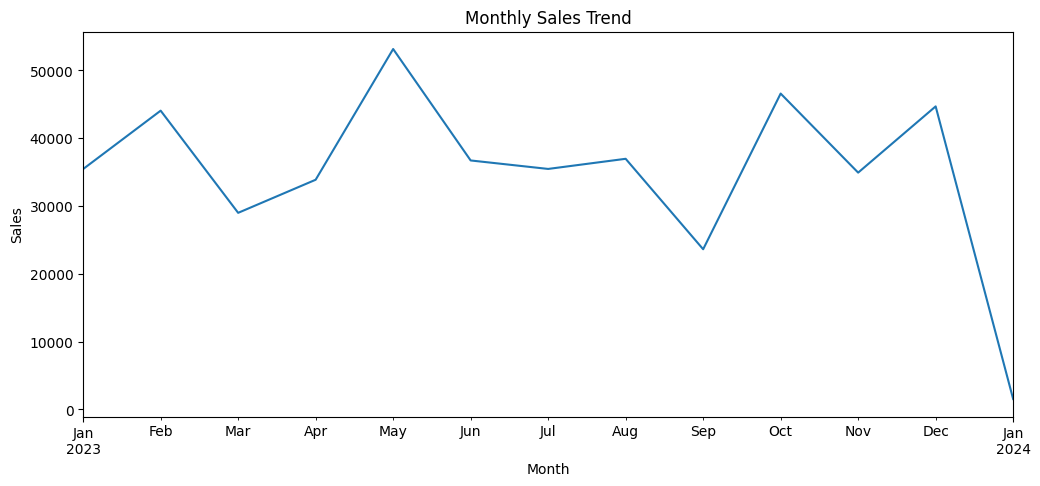

In [ ]:
monthly_sales.plot(kind='line',figsize=(12,5))

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Sales')
plt.show()

In [ ]:
quarterly_sales = df.groupby(
    df['Date'].dt.to_period('Q')
)['Sales'].sum()

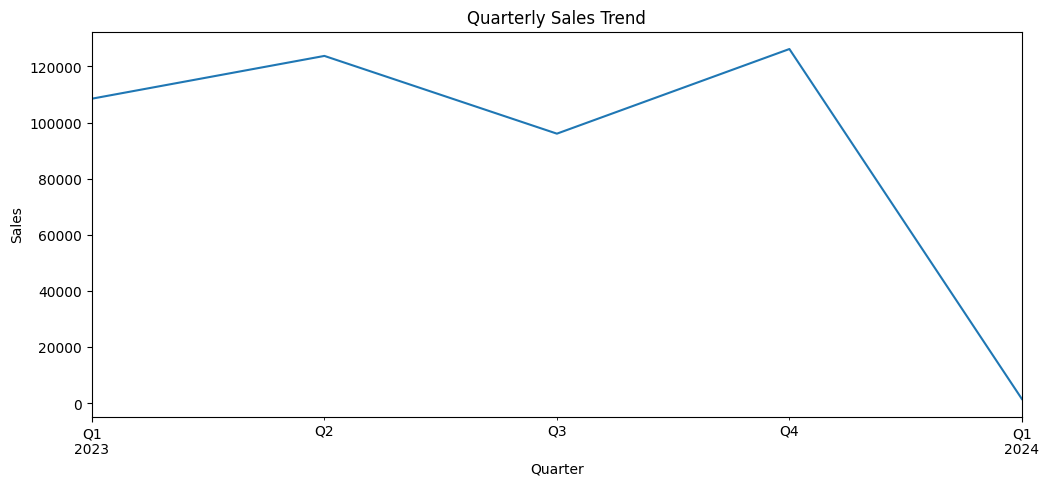

In [ ]:
quarterly_sales.plot(kind='line',figsize=(12,5))

plt.title('Quarterly Sales Trend')
plt.xlabel('Quarter')
plt.ylabel('Sales')
plt.show()

In [ ]:
### Observation:
'''
Sales show an increasing trend during the later months.
Some months have significantly higher sales, indicating seasonal
customer demand.
'''

'\nSales show an increasing trend during the later months.\nSome months have significantly higher sales, indicating seasonal\ncustomer demand.\n'

In [ ]:
## Step 11: Customer Demographic Analysis

In [ ]:
df['Age'].describe()
bins = [0,18,25,35,45,55,65,100]

labels = [
    'Below 18',
    '18-25',
    '26-35',
    '36-45',
    '46-55',
    '56-65',
    '65+'
]

df['Age_Group'] = pd.cut(df['Age'], bins=bins, labels=labels)

In [ ]:
df['Age_Group'].value_counts().sort_index()

,count
Age_Group,
Below 18,21
18-25,148
26-35,205
36-45,202
46-55,229
56-65,195
65+,0


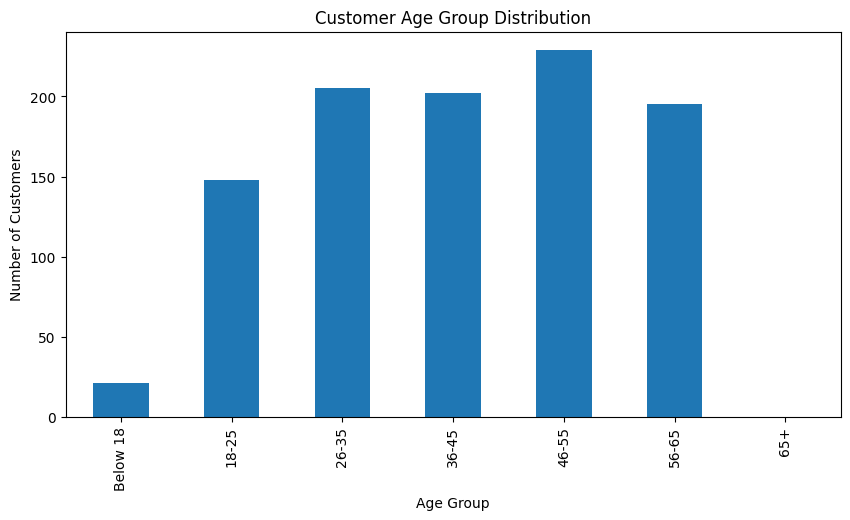

In [ ]:
df['Age_Group'].value_counts().sort_index().plot(
    kind = 'bar',
    figsize=(10,5)
)
plt.title('Customer Age Group Distribution')
plt.xlabel('Age Group')
plt.ylabel('Number of Customers')
plt.show()

In [ ]:
## Step 12: Gender Analysis

In [ ]:
df['Gender'].value_counts()

,count
Gender,
Female,510
Male,490


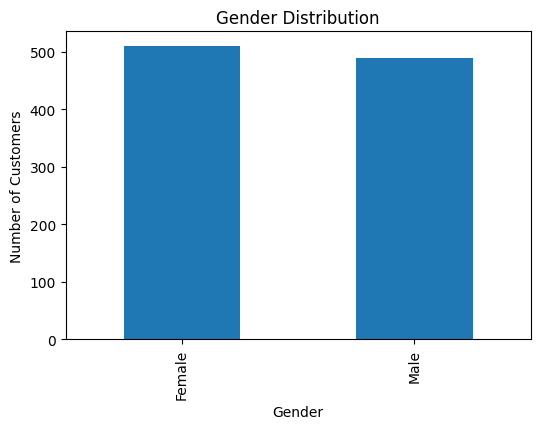

In [ ]:
df['Gender'].value_counts().plot(
    kind = 'bar',
    figsize=(6,4)
)
plt.title('Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Number of Customers')
plt.show()

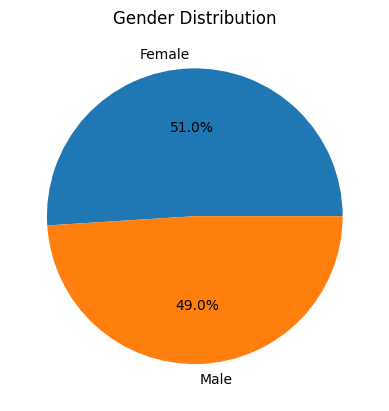

In [ ]:
df['Gender'].value_counts().plot(
    kind = 'pie',
    autopct = '%1.1f%%',
)
plt.title('Gender Distribution')
plt.ylabel('')
plt.show()

In [ ]:
## Step 13: Product Analysis

In [ ]:
top_products = df.groupby(
    'Product Category'
)['Quantity'].sum().sort_values(
    ascending = False
).head(10)
print(top_products)


Product Category
Clothing       894
Electronics    849
Beauty         771
Name: Quantity, dtype: int64


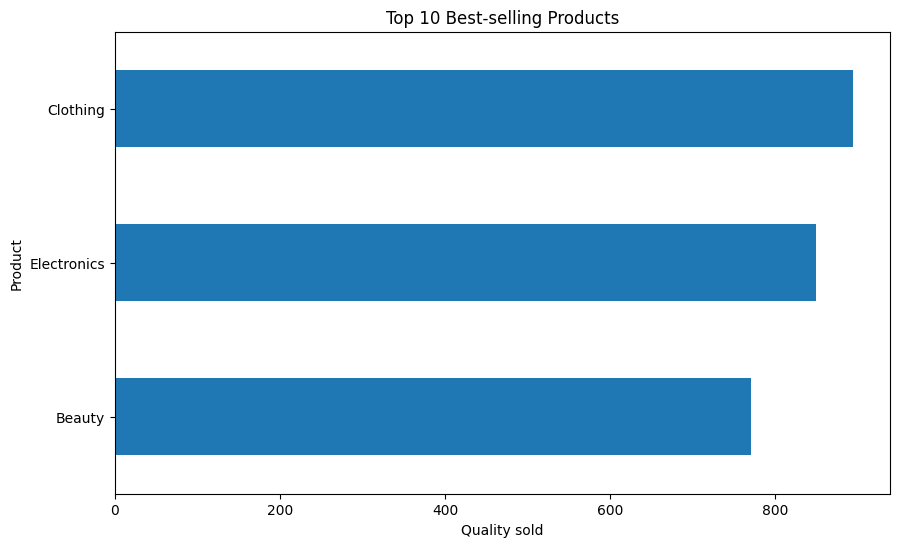

In [ ]:
top_products.sort_values().plot(
    kind = 'barh',
    figsize=(10,6)
)
plt.title('Top 10 Best-selling Products')
plt.xlabel('Quality sold')
plt.ylabel('Product')
plt.show()

In [ ]:
## Step 14 Revenue by product Category

In [ ]:
category_sales = df.groupby(
    'Product Category'
)['Sales'].sum().sort_values(ascending = False)

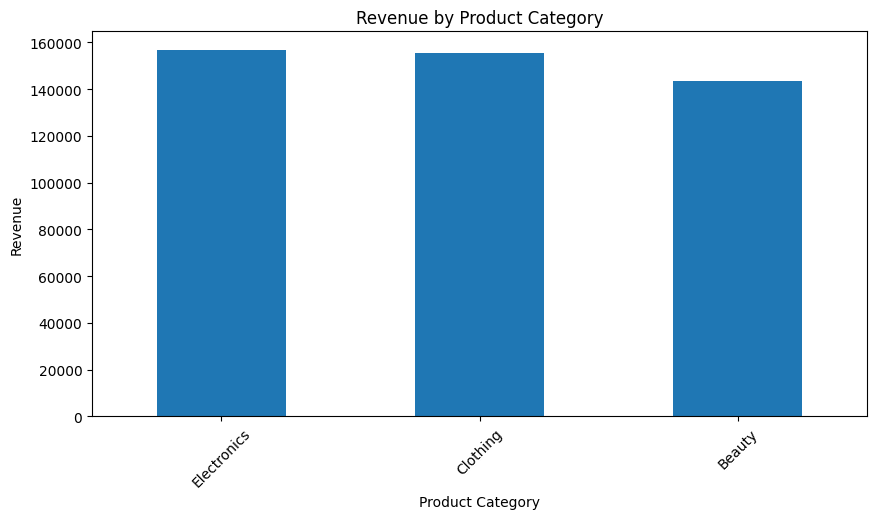

In [ ]:
category_sales.plot(
    kind = 'bar',
    figsize=(10,5)
)
plt.title('Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.show()

In [ ]:
## step 15 Heatmap / corrlation matrix

In [ ]:
corr = df.select_dtypes(
    include = np.number
).corr()

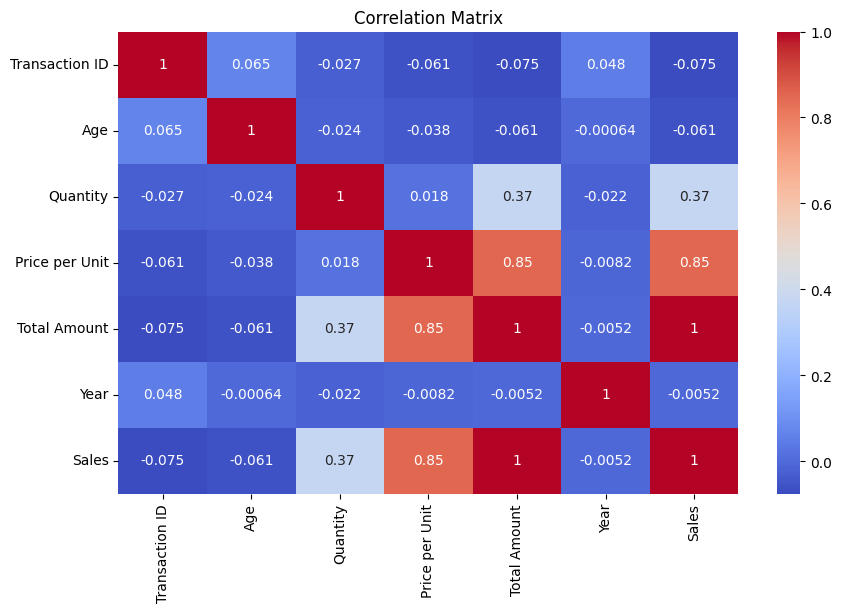

In [ ]:
plt.figure(figsize=(10,6))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm'
)
plt.title('Correlation Matrix')
plt.show()

In [ ]:
## step 16: Create one Addition Visualization

In [ ]:
age_sales = df.groupby(
    'Age_Group',
    observed = True
)['Sales'].sum()

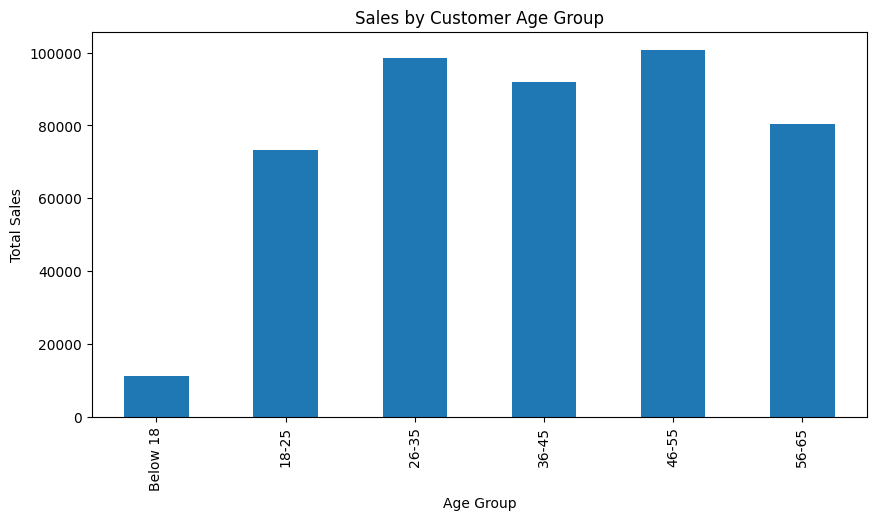

In [ ]:
age_sales.plot(
    kind = 'bar',
    figsize=(10,5)

)
plt.title('Sales by Customer Age Group')
plt.xlabel('Age Group')
plt.ylabel('Total Sales')
plt.show()

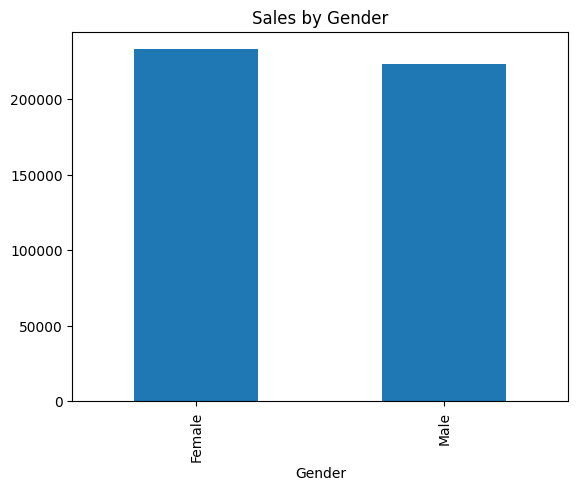

In [ ]:
gender_sales = df.groupby('Gender')['Sales'].sum()
gender_sales.plot(kind='bar')
plt.title('Sales by Gender')
plt.show()

In [ ]:
### Observation
'''
The sales trend shows that sales increase during certain months.
This may indicate seasonal demand. The business can increase
inventory and promotional activities during these high-demand periods.
'''

'\nThe sales trend shows that sales increase during certain months.\nThis may indicate seasonal demand. The business can increase\ninventory and promotional activities during these high-demand periods.\n'

In [ ]:
### Observation
'''
The 26–35 age group contributes the highest sales.
The company can therefore focus targeted marketing campaigns
towards this customer segment.
'''

'\nThe 26–35 age group contributes the highest sales.\nThe company can therefore focus targeted marketing campaigns\ntowards this customer segment.\n'

In [ ]:
### Observation
'''
The 26–35 age group contributes the highest sales.
The company can therefore focus targeted marketing campaigns
towards this customer segment.
'''

'\nThe 26–35 age group contributes the highest sales.\nThe company can therefore focus targeted marketing campaigns\ntowards this customer segment.\n'

In [ ]:
# Conclusion
'''
The exploratory data analysis provides useful insights into
sales trends, customer demographics, and product performance.

The analysis shows the most important sales periods, major customer
segments, and best-performing products. These findings can help
the business improve inventory planning, marketing strategies,
and customer targeting.
'''

'\nThe exploratory data analysis provides useful insights into\nsales trends, customer demographics, and product performance.\n\nThe analysis shows the most important sales periods, major customer\nsegments, and best-performing products. These findings can help\nthe business improve inventory planning, marketing strategies,\nand customer targeting.\n'

In [ ]:
# Actionable Business Recommendations

In [ ]:
'''
1. Focus on high-performing products

Increase inventory and promotional activities for the top-selling products.

2. Target high-value customer groups

Create personalized offers for the age group or gender generating the highest revenue.

3. Prepare for seasonal demand

Maintain sufficient inventory before months/quarters with higher sales
'''

'\n1. Focus on high-performing products\n\nIncrease inventory and promotional activities for the top-selling products.\n\n2. Target high-value customer groups\n\nCreate personalized offers for the age group or gender generating the highest revenue.\n\n3. Prepare for seasonal demand\n\nMaintain sufficient inventory before months/quarters with higher sales\n'